[1.00s] F detected, so to q1
[1.00s] Saved Position: (0.100, 0.100) , so to q2


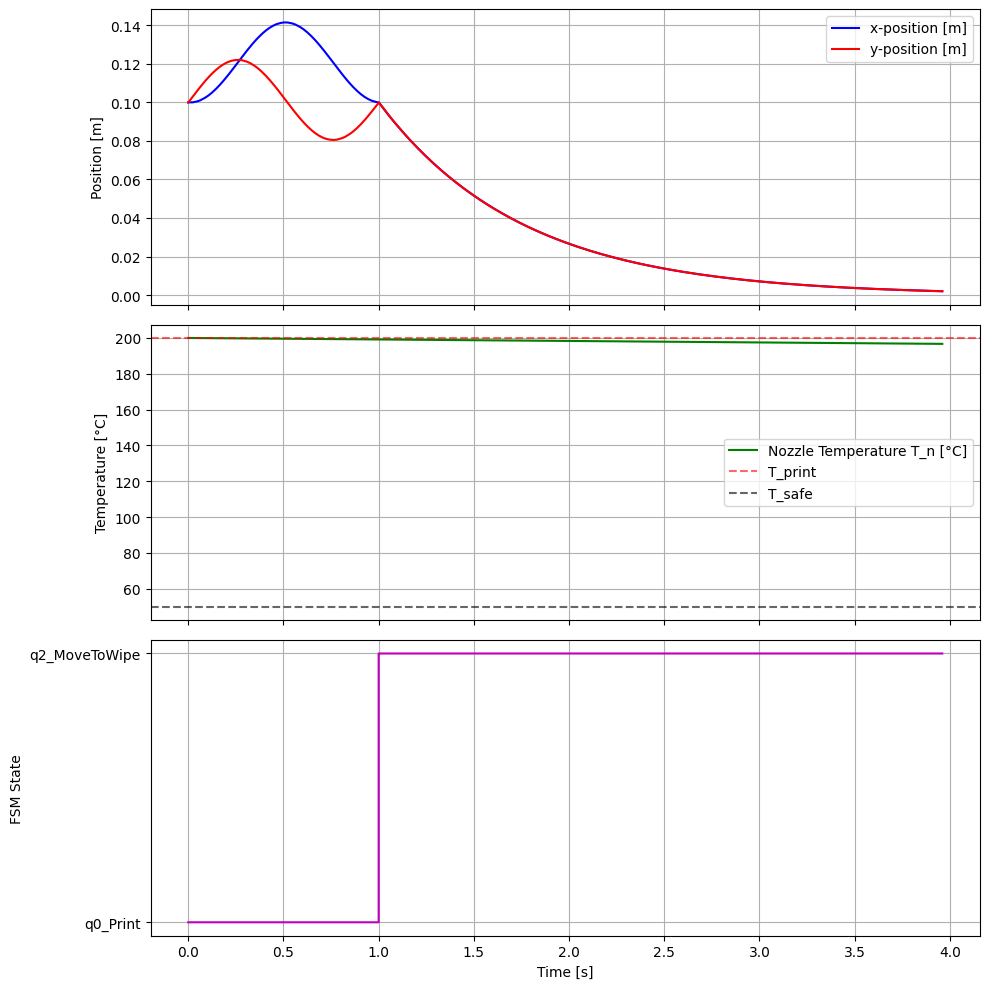

In [80]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

r_m = 0.0064       # Motor pulley radius [m]
L_m = 0.003      # Motor inductance [H]
R_m = 1.8        # Motor resistance [Ohm]
J_m = 5.7e-6      # Motor rotor inertia [kg*m^2]
K_m = 0.22       # Motor constant [Nm/A]
m = 0.6          # Tool head mass [kg]
J_tot = 18e-6  # Total effective inertia of the system
Max_x = 0.22       # Maximum x position [m]
Max_y = 0.22       # Maximum y position [m]
mu_r = 0.003     # Bearing rotational friction [Nm*s/rad]
mu_lx = 3      # Linear friction x-axes [N*s/m]
mu_ly = 3      # Linear friction y-axes [N*s/m]

C_tn = 15.0         # Thermische capaciteit nozzle [J/K]
R_tn = 12.0        # Thermische weerstand [K/W]
C_n = 100e-6       # Condensator nozzle [F]
R_n = 5.0          # Weerstand nozzle [Ohm]
L_n = 0.01         # Inductie nozzle [H]
T_e = 20.0        #Temperatuur omgeving [Celcius]

T_high = 200.0     # Gewenste printtemperatuur [°C]
T_low = 40.0       # Veilige wissel/afkoeltemperatuur [°C]
x_wipe = 0.0       # Wipe tower x-positie [m]
y_wipe = 0.0       # Wipe tower y-positie [m]

T_print = 200.0
T_safe = 50.0
WIPE_TIME = 2.0
LOAD_TIME = 3.0

def printer_dynamics(t, x_vec, u_vec):
    x, dx, ix, y, dy, iy, Tn, uCn, iLn = x_vec
    ux, uy, un = u_vec

    dxdt = np.zeros(9)

    dxdt[0] = dx
    dxdt[1] = -(mu_r/J_tot + (mu_lx * r_m**2)/(2 * J_tot)) * dx + (K_m * r_m / J_tot) * ix
    dxdt[2] = -(K_m / (L_m * r_m)) * dx - (R_m / L_m) * ix + (1 / L_m) * ux
    dxdt[3] = dy
    dxdt[4] = -(mu_r/J_tot + (mu_ly * r_m**2)/(2 * J_tot)) * dy + (K_m * r_m / J_tot) * iy
    dxdt[5] = -(K_m / (L_m * r_m)) * dy - (R_m / L_m) * iy + (1 / L_m) * uy
    dxdt[6] = -1.0 / (C_tn * R_tn) * Tn + uCn / (C_tn * R_n) + T_e / (C_tn * R_tn)
    dxdt[7] = -1.0 / (C_n * R_n) * uCn + (1.0 / C_n) * iLn
    dxdt[8] = -1.0 / L_n * uCn + (1.0 / L_n) * un
    return dxdt

#State q2 and q7
def position_controller(x_curr, y_curr, x_target, y_target, Kp=50.0):
    ux = Kp * (x_target - x_curr)
    uy = Kp * (y_target - y_curr)
    # Voltage limits on 24
    ux = np.clip(ux, -24.0, 24.0)
    uy = np.clip(uy, -24.0, 24.0)
    return ux, uy

#FSM hybrid system
def run_hybrid_simulation():
    x0 = np.array([0.1, 0.0, 0.0, 0.1, 0.0, 0.0, T_print, np.sqrt(T_print * R_n / R_tn), 0.0])
    
    state = 'q0_Print'
    t_current = 0.0
    x_saved, y_saved = 0.0, 0.0
    timer_start = 0.0
    
    history_t = []
    history_x = []
    history_states = []
    
    trigger_F_time = 1.0 
    
    for step in range(200): 
        
        if state == 'q0_Print':
            #Drawing circle
            omega = 2.0 * np.pi
            ux = 5.0 * np.sin(omega * t_current)
            uy = 5.0 * np.cos(omega * t_current)
            un = 12.0 
            
            if t_current >= trigger_F_time:
                state = 'q1_Save'
                print(f"[{t_current:.2f}s] F detected, so to q1")
                continue

        elif state == 'q1_Save':
            # Save current location
            x_saved, y_saved = x0[0], x0[3]
            ux, uy, un = 0.0, 0.0, 12.0
            print(f"[{t_current:.2f}s] Saved Position: ({x_saved:.3f}, {y_saved:.3f}) , so to q2")
            state = 'q2_MoveToWipe'
            continue

        elif state == 'q2_MoveToWipe':
            # Drive to (0,0)
            ux, uy = position_controller(x0[0], x0[3], 0.0, 0.0)
            un = 12.0
            #Guard check near 0,0
            if np.hypot(x0[0], x0[3]) < 0.002 and np.hypot(x0[1], x0[4]) < 0.01:
                state = 'q3_Wipe'
                timer_start = t_current
                print(f"[{t_current:.2f}s] At (0,0), so to q3_Wipe")
                continue

        elif state == 'q3_Wipe':
            ux, uy, un = 0.0, 0.0, 12.0
            if t_current - timer_start >= WIPE_TIME:
                state = 'q4_HeatOff'
                print(f"[{t_current:.2f}s] wipe done, so to q4")
                continue

        elif state == 'q4_HeatOff':
            ux, uy, un = 0.0, 0.0, 0.0 # Heat Off
            # Guard check safe temp
            if x0[6] <= T_safe:
                state = 'q5_Load'
                timer_start = t_current
                print(f"[{t_current:.2f}s] T_n <= T_safe reached ({x0[6]:.1f}°C), so to q5")
                continue

        elif state == 'q5_Load':
            ux, uy, un = 0.0, 0.0, 0.0
            if t_current - timer_start >= LOAD_TIME:
                state = 'q6_HeatOn'
                print(f"[{t_current:.2f}s] Reloaded so to q6")
                continue

        elif state == 'q6_HeatOn':
            ux, uy, un = 0.0, 0.0, 24.0 
            # Guard check temp is on target level
            if x0[6] >= T_print:
                state = 'q7_ReturnToPrint'
                print(f"[{t_current:.2f}s] T_n >= T_print reached ({x0[6]:.1f}°C), so to q7")
                continue

        elif state == 'q7_ReturnToPrint':
            ux, uy = position_controller(x0[0], x0[3], x_saved, y_saved)
            un = 12.0
            # Guard return to saved position
            if np.hypot(x0[0] - x_saved, x0[3] - y_saved) < 0.002:
                state = 'q0_Print'
                print(f"[{t_current:.2f}s] Returned to Saved Location -> Resume q0_Print")
                break

        dt = 0.02
        t_span = (t_current, t_current + dt)
        u_input = [ux, uy, un]
        
        sol = solve_ivp(printer_dynamics, t_span, x0, args=(u_input,))
        
        history_t.extend(sol.t)
        history_x.extend(sol.y.T)
        history_states.extend([state] * len(sol.t))
        
        x0 = sol.y[:, -1]
        t_current = sol.t[-1]

    return np.array(history_t), np.array(history_x), history_states

t, x_data, states = run_hybrid_simulation()

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

axes[0].plot(t, x_data[:, 0], label='x-position [m]', color='b')
axes[0].plot(t, x_data[:, 3], label='y-position [m]', color='r')
axes[0].set_ylabel('Position [m]')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(t, x_data[:, 6], label='Nozzle Temperature T_n [°C]', color='g')
axes[1].axhline(T_print, linestyle='--', color='r', alpha=0.6, label='T_print')
axes[1].axhline(T_safe, linestyle='--', color='k', alpha=0.6, label='T_safe')
axes[1].set_ylabel('Temperature [°C]')
axes[1].legend()
axes[1].grid(True)

unique_states = sorted(list(set(states)), key=lambda s: states.index(s))
state_indices = [unique_states.index(s) for s in states]
axes[2].step(t, state_indices, where='post', color='m')
axes[2].set_yticks(range(len(unique_states)))
axes[2].set_yticklabels(unique_states)
axes[2].set_ylabel('FSM State')
axes[2].set_xlabel('Time [s]')
axes[2].grid(True)

plt.tight_layout()
plt.show()
